In [1]:
import pandas as pd

In [13]:
df = pd.DataFrame({
    "Record": [
        "id=105; user=Alice; score=92",
        "id=106; user=Bob; score=88",
        "id=107; user=Carol; score=95"
    ]
})

df

,Record
0,id=105; user=Alice; score=92
1,id=106; user=Bob; score=88
2,id=107; user=Carol; score=95


In [14]:
# извлечь вотдельные колонки user и score
# использовать метод extract и регулярное выражение
# r"user=(?P<user>[^;]+);\s*score=(?P<score>\d+)"
extracted = df["Record"].str.extract(r"user=(?P<user>[^;]+);\s*score=(?P<score>\d+)")

In [15]:
extracted

,user,score
0,Alice,92
1,Bob,88
2,Carol,95


In [16]:
print(extracted.dtypes)

user     object
score    object
dtype: object


In [17]:
# 1) для датафрейма extracted преобразуем в колонке score тип данных к int
extracted["score"] = extracted["score"].astype(int)
print(extracted.dtypes)


user     object
score     int64
dtype: object


In [18]:
# 2) объединим с исходным датафреймом
# concat ... df, extracted
df = pd.concat([df, extracted], axis = 1)
df

,Record,user,score
0,id=105; user=Alice; score=92,Alice,92
1,id=106; user=Bob; score=88,Bob,88
2,id=107; user=Carol; score=95,Carol,95


In [20]:
# создадим датафрейм с колонками name age и в них по 3 строки
# новый датафрейм сдвумя строками тех же колонок.
df_one = pd.DataFrame({
    'Name': ['name_1', 'name_2', 'name_3'],
    'Age': [30, 31, 35]
})

df_two = pd.DataFrame({
    'Name': ['name_4', 'name_5'],
    'Age': [30, 31]
})
# объединим датафрейм + сделаем переиндексацию (в качестве второго параметра метода concat 
# надо передать параметр ignore_index=True (перенумеровывание индекса))

df_all = pd.concat([df_one, df_two], ignore_index=True)
df_all

,Name,Age
0,name_1,30
1,name_2,31
2,name_3,35
3,name_4,30
4,name_5,31


In [21]:
# df_all
# to_csv to_excel to_json
# read_excel read_csv read_json

df_all

,Name,Age
0,name_1,30
1,name_2,31
2,name_3,35
3,name_4,30
4,name_5,31


In [24]:
json_path = 'df_all.json'
df_all.to_json(json_path, orient='records', force_ascii=False)

In [25]:
df_from_json = pd.read_json(json_path, orient='records')

In [26]:
df_from_json

,Name,Age
0,name_1,30
1,name_2,31
2,name_3,35
3,name_4,30
4,name_5,31


In [27]:
import matplotlib.pyplot as plt # визуализация

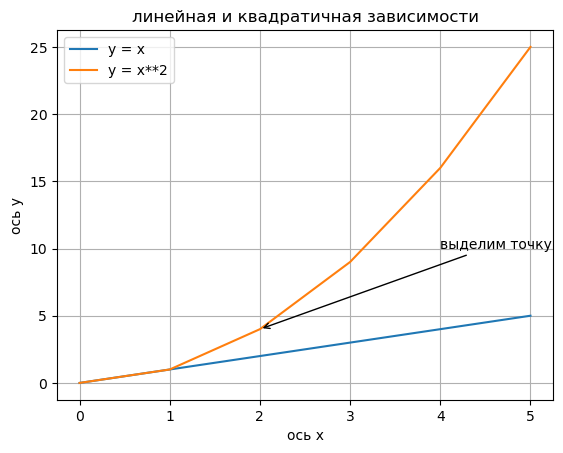

In [37]:
x = [i for i in range(6)]
y1 = [i for i in x] # линейная
y2 = [i**2 for i in x] # квадратичная

fig, ax = plt.subplots()

ax.plot(x, y1, label="y = x")
ax.plot(x, y2, label="y = x**2")
ax.set_title("линейная и квадратичная зависимости")
ax.set_xlabel("ось x")
ax.set_ylabel("ось у")
ax.grid(True)  # сетка на графике
ax.legend()
ax.annotate("выделим точку", xy=(2, 4), xytext=(4, 10),
           arrowprops=dict(arrowstyle='->'))

plt.show()

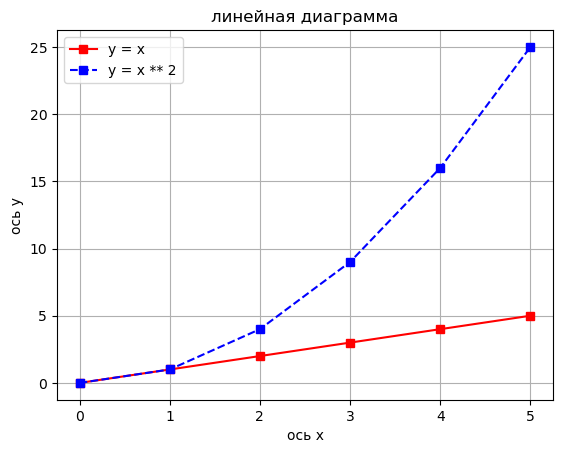

In [39]:
x = [i for i in range(6)]
y1 = [i for i in x] # линейная
y2 = [i**2 for i in x] # квадратичная

# линейные диаграммы с разными стилями
# для линейной функции сделаем красный цвет marker...
# для квадратичной функции сделаем синий цвет linestyle='--'
plt.plot(x, y1, color="red", marker="s", label='y = x')
plt.plot(x, y2, color='blue', marker="s", linestyle='--', label='y = x ** 2')

plt.title("линейная диаграмма")
plt.xlabel("ось х")
plt.ylabel("ось y")
plt.grid(True)
plt.legend()
plt.show()

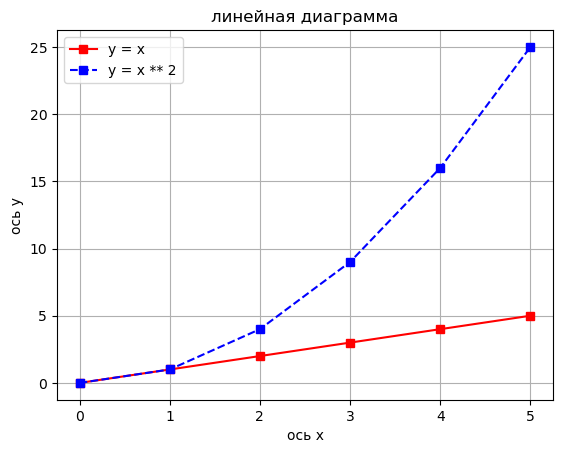

In [42]:
# x = [i for i in range(6)]
# y1 = [i for i in x] # линейная
# y2 = [i**2 for i in x] # квадратичная

# x y1 y2 - чеоез numpy сформируйте данные
import numpy as np
x = np.linspace(0, 5, 6)
y1 = x
y2 = x ** 2

# линейные диаграммы с разными стилями
# для линейной функции сделаем красный цвет marker...
# для квадратичной функции сделаем синий цвет linestyle='--'
plt.plot(x, y1, color="red", marker="s", label='y = x')
plt.plot(x, y2, color='blue', marker="s", linestyle='--', label='y = x ** 2')

plt.title("линейная диаграмма")
plt.xlabel("ось х")
plt.ylabel("ось y")
plt.grid(True)
plt.legend()
plt.show()

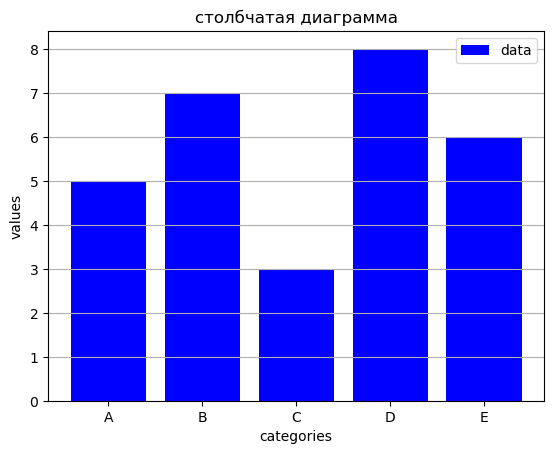

In [47]:
categories = ['A', 'B', 'C', 'D', 'E']
values = np.array([5, 7, 3, 8, 6])

# Bar (столббчатая диаграмма)

plt.bar(categories, values, color="blue", label="data")
plt.title('столбчатая диаграмма')
plt.xlabel('categories')
plt.ylabel('values')
plt.legend()
plt.grid(axis='y') #  только по y - горизонтальная сетка

plt.show()

In [16]:
# загрузим данные в датафрейм
df = pd.read_csv('MoviesOnStreamingPlatforms.csv')
df

,Unnamed: 0,ID,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+,Type
0,0,1,The Irishman,2019,18+,98/100,1,0,0,0,0
1,1,2,Dangal,2016,7+,97/100,1,0,0,0,0
2,2,3,David Attenborough: A Life on Our Planet,2020,7+,95/100,1,0,0,0,0
3,3,4,Lagaan: Once Upon a Time in India,2001,7+,94/100,1,0,0,0,0
4,4,5,Roma,2018,18+,94/100,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
9510,9510,9511,Most Wanted Sharks,2020,NaN,14/100,0,0,0,1,0
9511,9511,9512,Doc McStuffins: The Doc Is In,2020,NaN,13/100,0,0,0,1,0
9512,9512,9513,Ultimate Viking Sword,2019,NaN,13/100,0,0,0,1,0
9513,9513,9514,Hunt for the Abominable Snowman,2011,NaN,10/100,0,0,0,1,0


In [9]:
# выведем общую информацию о данных из датасета
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9515 entries, 0 to 9514
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Unnamed: 0       9515 non-null   int64 
 1   ID               9515 non-null   int64 
 2   Title            9515 non-null   object
 3   Year             9515 non-null   int64 
 4   Age              5338 non-null   object
 5   Rotten Tomatoes  9508 non-null   object
 6   Netflix          9515 non-null   int64 
 7   Hulu             9515 non-null   int64 
 8   Prime Video      9515 non-null   int64 
 9   Disney+          9515 non-null   int64 
 10  Type             9515 non-null   int64 
dtypes: int64(8), object(3)
memory usage: 817.8+ KB
None


In [17]:
# выведем 5 первых строк для обзора данных
df.head(5)

,Unnamed: 0,ID,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+,Type
0,0,1,The Irishman,2019,18+,98/100,1,0,0,0,0
1,1,2,Dangal,2016,7+,97/100,1,0,0,0,0
2,2,3,David Attenborough: A Life on Our Planet,2020,7+,95/100,1,0,0,0,0
3,3,4,Lagaan: Once Upon a Time in India,2001,7+,94/100,1,0,0,0,0
4,4,5,Roma,2018,18+,94/100,1,0,0,0,0


In [18]:
# .drop - удалить ненужные столбцы -  	Unnamed: 0  ID 
df.drop(columns=['Unnamed: 0','ID','Type'], inplace = True)
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9515 entries, 0 to 9514
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Title            9515 non-null   object
 1   Year             9515 non-null   int64 
 2   Age              5338 non-null   object
 3   Rotten Tomatoes  9508 non-null   object
 4   Netflix          9515 non-null   int64 
 5   Hulu             9515 non-null   int64 
 6   Prime Video      9515 non-null   int64 
 7   Disney+          9515 non-null   int64 
dtypes: int64(5), object(3)
memory usage: 594.8+ KB
None


In [19]:
df.head(5)

,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+
0,The Irishman,2019,18+,98/100,1,0,0,0
1,Dangal,2016,7+,97/100,1,0,0,0
2,David Attenborough: A Life on Our Planet,2020,7+,95/100,1,0,0,0
3,Lagaan: Once Upon a Time in India,2001,7+,94/100,1,0,0,0
4,Roma,2018,18+,94/100,1,0,0,0


# обработать столбец Age - заполним пропуски значением Unknown


In [20]:
# fillna
df['Age'].fillna('Unknown', inplace=True)

In [21]:
print(df.info())
df.head(50)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9515 entries, 0 to 9514
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Title            9515 non-null   object
 1   Year             9515 non-null   int64 
 2   Age              9515 non-null   object
 3   Rotten Tomatoes  9508 non-null   object
 4   Netflix          9515 non-null   int64 
 5   Hulu             9515 non-null   int64 
 6   Prime Video      9515 non-null   int64 
 7   Disney+          9515 non-null   int64 
dtypes: int64(5), object(3)
memory usage: 594.8+ KB
None


,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+
0,The Irishman,2019,18+,98/100,1,0,0,0
1,Dangal,2016,7+,97/100,1,0,0,0
2,David Attenborough: A Life on Our Planet,2020,7+,95/100,1,0,0,0
3,Lagaan: Once Upon a Time in India,2001,7+,94/100,1,0,0,0
4,Roma,2018,18+,94/100,1,0,0,0
5,To All the Boys I've Loved Before,2018,13+,94/100,1,0,0,0
6,The Social Dilemma,2020,13+,93/100,1,0,0,0
7,Okja,2017,13+,92/100,1,0,0,0
8,The Ballad of Buster Scruggs,2018,16+,92/100,1,0,0,0
9,The Trial of the Chicago 7,2020,18+,92/100,1,0,0,0


In [1]:
import pandas as pd
import matplotlib.pyplot as plt # визуализация

In [22]:
df

,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+
0,The Irishman,2019,18+,98/100,1,0,0,0
1,Dangal,2016,7+,97/100,1,0,0,0
2,David Attenborough: A Life on Our Planet,2020,7+,95/100,1,0,0,0
3,Lagaan: Once Upon a Time in India,2001,7+,94/100,1,0,0,0
4,Roma,2018,18+,94/100,1,0,0,0
...,...,...,...,...,...,...,...,...
9510,Most Wanted Sharks,2020,Unknown,14/100,0,0,0,1
9511,Doc McStuffins: The Doc Is In,2020,Unknown,13/100,0,0,0,1
9512,Ultimate Viking Sword,2019,Unknown,13/100,0,0,0,1
9513,Hunt for the Abominable Snowman,2011,Unknown,10/100,0,0,0,1


In [23]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9515 entries, 0 to 9514
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Title            9515 non-null   object
 1   Year             9515 non-null   int64 
 2   Age              9515 non-null   object
 3   Rotten Tomatoes  9508 non-null   object
 4   Netflix          9515 non-null   int64 
 5   Hulu             9515 non-null   int64 
 6   Prime Video      9515 non-null   int64 
 7   Disney+          9515 non-null   int64 
dtypes: int64(5), object(3)
memory usage: 594.8+ KB
None


In [25]:
# для колонки Rotten Tomatoes (рейтинг) удалим постфикс "/100"  # str.replace
df["Rotten Tomatoes"] = df["Rotten Tomatoes"].str.replace('/100', '') 
# преобразуем к числовому типу данных # to_numeric (метод библиотеки pandas)
df["Rotten Tomatoes"] = pd.to_numeric(df["Rotten Tomatoes"], errors='coerce')


In [26]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9515 entries, 0 to 9514
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            9515 non-null   object 
 1   Year             9515 non-null   int64  
 2   Age              9515 non-null   object 
 3   Rotten Tomatoes  9508 non-null   float64
 4   Netflix          9515 non-null   int64  
 5   Hulu             9515 non-null   int64  
 6   Prime Video      9515 non-null   int64  
 7   Disney+          9515 non-null   int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 594.8+ KB
None


In [27]:
# шаг 3 - 3   Rotten Tomatoes  9508 non-null   object (в колонке есть Nan значения)
# нужно заменить их на числовое значение, на медианные значением. 
# .median() | fillna
median_rating = df['Rotten Tomatoes'].median()
df['Rotten Tomatoes'].fillna(median_rating, inplace=True)

In [28]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9515 entries, 0 to 9514
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            9515 non-null   object 
 1   Year             9515 non-null   int64  
 2   Age              9515 non-null   object 
 3   Rotten Tomatoes  9515 non-null   float64
 4   Netflix          9515 non-null   int64  
 5   Hulu             9515 non-null   int64  
 6   Prime Video      9515 non-null   int64  
 7   Disney+          9515 non-null   int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 594.8+ KB
None


In [29]:
df.head(6)

,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+
0,The Irishman,2019,18+,98.0,1,0,0,0
1,Dangal,2016,7+,97.0,1,0,0,0
2,David Attenborough: A Life on Our Planet,2020,7+,95.0,1,0,0,0
3,Lagaan: Once Upon a Time in India,2001,7+,94.0,1,0,0,0
4,Roma,2018,18+,94.0,1,0,0,0
5,To All the Boys I've Loved Before,2018,13+,94.0,1,0,0,0


In [30]:
# посчитаем количество фильнов на кадой платформе (выведем в формате словаря) Rotten Tomatoes 	Netflix 	Hulu 	Prime Video 	Disney+
platform_counts = {
    "Netflix": df['Netflix'].sum(),
    "Hulu": df['Hulu'].sum(),
    "Prime Video": df['Prime Video'].sum(),
    "Disney+": df['Disney+'].sum()
}

print(f"Количество фильмов на каждой платформе {platform_counts}")

Количество фильмов на каждой платформе {'Netflix': 3695, 'Hulu': 1047, 'Prime Video': 4113, 'Disney+': 922}


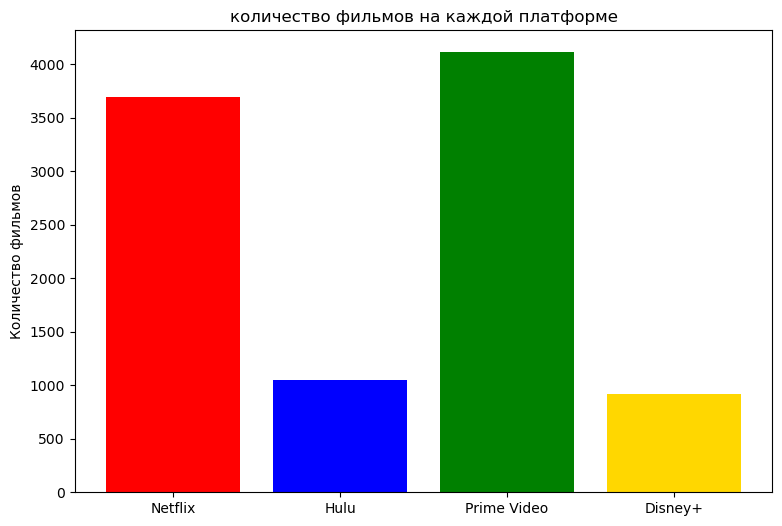

In [36]:
# Построим столбчатую вертикальную диаграмму (bar) числа фильмов на каждой платформе.
# .figure(figsize=(9,6))
plt.figure(figsize=(9,6))
plt.bar(platform_counts.keys(), platform_counts.values(), color=['red', 'blue', 'green', 'gold'])
plt.title("количество фильмов на каждой платформе")
plt.ylabel("Количество фильмов")

plt.show()

**Prime video предлагает больше всего фильмов**

In [37]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9515 entries, 0 to 9514
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            9515 non-null   object 
 1   Year             9515 non-null   int64  
 2   Age              9515 non-null   object 
 3   Rotten Tomatoes  9515 non-null   float64
 4   Netflix          9515 non-null   int64  
 5   Hulu             9515 non-null   int64  
 6   Prime Video      9515 non-null   int64  
 7   Disney+          9515 non-null   int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 594.8+ KB
None


In [38]:
df.head(3)

,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+
0,The Irishman,2019,18+,98.0,1,0,0,0
1,Dangal,2016,7+,97.0,1,0,0,0
2,David Attenborough: A Life on Our Planet,2020,7+,95.0,1,0,0,0


In [39]:
# распределение фильмов по возрастным рейтингам (Age) в формате (bar)
# age_counts .... .value_counts()
age_counts = df['Age'].value_counts()
# ось x - возратной рейтинг
# ось y - колличество филлльмов
age_counts

Age
Unknown    4177
18+        2276
7+         1090
13+         998
all         698
16+         276
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

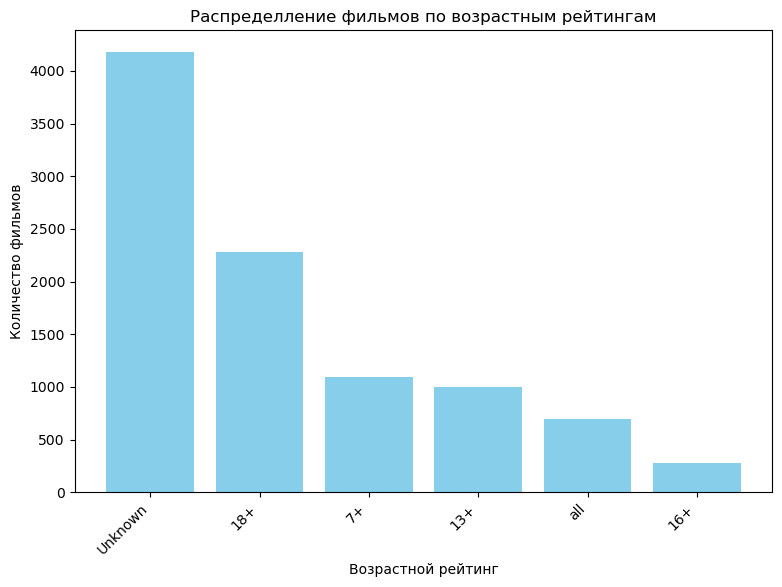

In [46]:
plt.figure(figsize=(9,6))
plt.bar(age_counts.index, age_counts.values, color='skyblue')
plt.title("Распределление фильмов по возрастным рейтингам")
plt.xlabel("Возрастной рейтинг")
plt.ylabel("Количество фильмов")
plt.xticks(rotation=45, ha='right')

plt.show

# data

## data
text
**text**

In [44]:
df.head(5)

,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+
0,The Irishman,2019,18+,98.0,1,0,0,0
1,Dangal,2016,7+,97.0,1,0,0,0
2,David Attenborough: A Life on Our Planet,2020,7+,95.0,1,0,0,0
3,Lagaan: Once Upon a Time in India,2001,7+,94.0,1,0,0,0
4,Roma,2018,18+,94.0,1,0,0,0


In [ ]:
# визуализация распределения фильмов по десятилетиям.
# нужно создать новую колонку на основе колонки Year

In [47]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9515 entries, 0 to 9514
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            9515 non-null   object 
 1   Year             9515 non-null   int64  
 2   Age              9515 non-null   object 
 3   Rotten Tomatoes  9515 non-null   float64
 4   Netflix          9515 non-null   int64  
 5   Hulu             9515 non-null   int64  
 6   Prime Video      9515 non-null   int64  
 7   Disney+          9515 non-null   int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 594.8+ KB
None


In [49]:
df['Decades'] = (df['Year'] // 10) * 10
decades_couts = df['Decades'].value_counts().sort_index()
decades_couts

Decades
1910       5
1920      15
1930     161
1940     174
1950     174
1960     112
1970     219
1980     307
1990     506
2000    1294
2010    5359
2020    1189
Name: count, dtype: int64

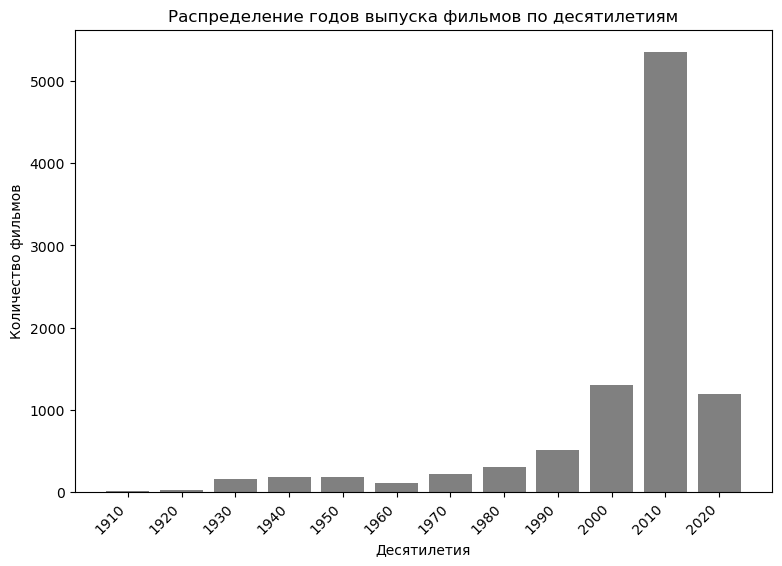

In [66]:
plt.figure(figsize=(9,6))
plt.bar(decades_couts.index.astype(str), decades_couts.values, color='grey')
plt.title("Распределение годов выпуска фильмов по десятилетиям")
plt.xlabel("Десятилетия")
plt.ylabel("Количество фильмов")

plt.xticks(rotation=45, ha='right')

plt.show()

In [50]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9515 entries, 0 to 9514
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Title            9515 non-null   object 
 1   Year             9515 non-null   int64  
 2   Age              9515 non-null   object 
 3   Rotten Tomatoes  9515 non-null   float64
 4   Netflix          9515 non-null   int64  
 5   Hulu             9515 non-null   int64  
 6   Prime Video      9515 non-null   int64  
 7   Disney+          9515 non-null   int64  
 8   Decades          9515 non-null   int64  
dtypes: float64(1), int64(6), object(2)
memory usage: 669.2+ KB
None


In [67]:
df.head(2)

,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+,Decades
0,The Irishman,2019,18+,98.0,1,0,0,0,2010
1,Dangal,2016,7+,97.0,1,0,0,0,2010


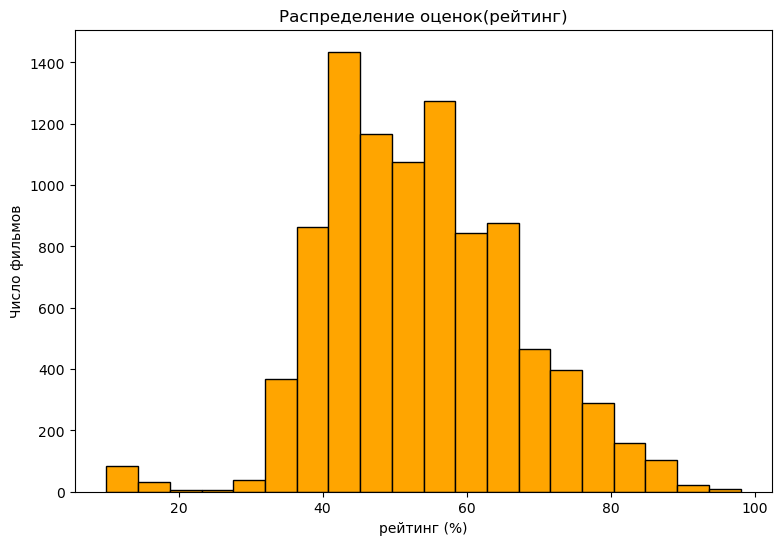

In [69]:
# hist Распределение оценок рейтинга (Rotten Tomatoes)
ratings = df["Rotten Tomatoes"]

plt.figure(figsize=(9,6))
plt.hist(ratings, bins=20, color='orange', edgecolor='black')
plt.title("Распределение оценок(рейтинг)")
plt.xlabel("рейтинг (%)")
plt.ylabel("Число фильмов")

plt.show()


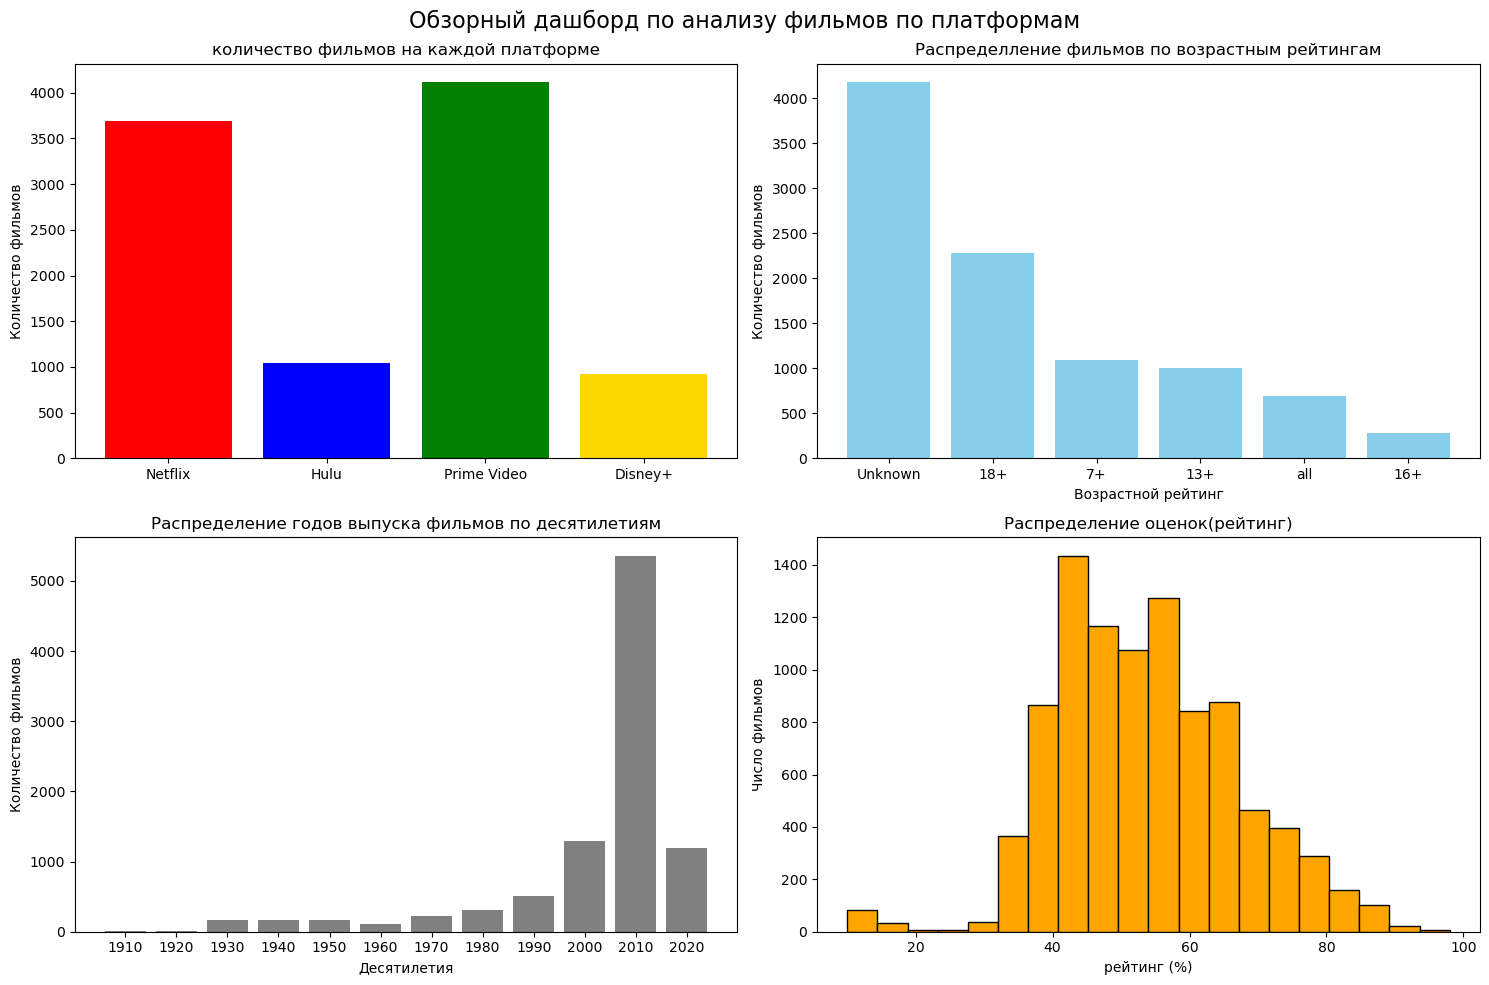

In [85]:
fig, ax = plt.subplots(2, 2, figsize=(15,10))
fig.suptitle("Обзорный дашборд по анализу фильмов по платформам", fontsize=16)


ax[0,0].bar(platform_counts.keys(), platform_counts.values(), color=['red', 'blue', 'green', 'gold'])
ax[0,0].set_title("количество фильмов на каждой платформе")
ax[0,0].set_ylabel("Количество фильмов")

ax[0,1].bar(age_counts.index, age_counts.values, color='skyblue')
ax[0,1].set_title("Распределление фильмов по возрастным рейтингам")
ax[0,1].set_xlabel("Возрастной рейтинг")
ax[0,1].set_ylabel("Количество фильмов")


ax[1,0].bar(decades_couts.index.astype(str), decades_couts.values, color='grey')
ax[1,0].set_title("Распределение годов выпуска фильмов по десятилетиям")
ax[1,0].set_xlabel("Десятилетия")
ax[1,0].set_ylabel("Количество фильмов")

ax[1,1].hist(ratings, bins=20, color='orange', edgecolor='black')
ax[1,1].set_title("Распределение оценок(рейтинг)")
ax[1,1].set_xlabel("рейтинг (%)")
ax[1,1].set_ylabel("Число фильмов")

plt.tight_layout()
plt.show()